# Diagnóstico de falhas em rolamentos com vibração — CWRU (48 kHz, carga 1 hp)
**Pipeline:** sinal bruto → janelas → features (tempo, FFT, espectro de envelope) → classificadores → avaliação sem vazamento.

**Como rodar:** descompacte o `archive.zip` na mesma pasta do notebook (deve existir a pasta `raw/`). Requer `numpy scipy pandas scikit-learn matplotlib seaborn`.

**Dados:** 10 classes — Normal e falhas de pista interna (IR), esfera (B) e pista externa (OR, posição 6h) com diâmetros 0,007", 0,014" e 0,021". Canal usado: acelerômetro do lado acionado (DE), 48 kHz, ~1772 rpm.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
plt.rcParams.update({"figure.dpi":110,"axes.grid":True,"grid.alpha":.3})

## 1. Funções (carga, janelamento, features)

In [2]:
import re
import numpy as np
import scipy.io as sio
from scipy import signal, stats

FS = 48_000
WIN = 4096          # ~0,085 s, ~2,5 rotações
STEP = 2048         # 50% de sobreposição
import os
RAW = "raw" if os.path.isdir("raw") else "archive/raw"

# arquivo -> (rótulo, id do arquivo no CWRU)
FILES = {
    "Time_Normal_1_098.mat": ("Normal", "098"),
    "IR007_1_110.mat": ("IR007", "110"),
    "IR014_1_175.mat": ("IR014", "175"),
    "IR021_1_214.mat": ("IR021", "214"),
    "B007_1_123.mat": ("B007", "123"),
    "B014_1_190.mat": ("B014", "190"),
    "B021_1_227.mat": ("B021", "227"),
    "OR007_6_1_136.mat": ("OR007", "136"),
    "OR014_6_1_202.mat": ("OR014", "202"),
    "OR021_6_1_239.mat": ("OR021", "239"),
}

# Rolamento SKF 6205-2RS (lado acionado, DE): ordens de falha (x frequência de rotação)
ORDERS = {"BPFI": 5.4152, "BPFO": 3.5848, "BSF": 4.7135}


def load_signal(fname):
    """Retorna (sinal DE, rpm). Pega a variável pelo id do arquivo (IR014 tem uma X217 sobrando)."""
    label, fid = FILES[fname]
    m = sio.loadmat(f"{RAW}/{fname}")
    x = np.ravel(m[f"X{fid}_DE_time"]).astype(float)
    rpm = [float(np.ravel(v)[0]) for k, v in m.items() if k.endswith("RPM")]
    rpm = rpm[0] if rpm else 1772.0  # Normal sem RPM no .mat: usa 1772 (carga 1 hp)
    return x, rpm


def windows(x, win=WIN, step=STEP):
    n = (len(x) - win) // step + 1
    idx = np.arange(win)[None, :] + step * np.arange(n)[:, None]
    return x[idx]


def block_split(n, train_frac=0.7, gap=2):
    """Divisão em blocos contíguos no tempo (com folga) para evitar vazamento por sobreposição."""
    cut = int(n * train_frac)
    return np.arange(0, cut), np.arange(cut + gap, n)


# ------------------------- features -------------------------
def time_features(w):
    rms = np.sqrt(np.mean(w ** 2))
    pk = np.max(np.abs(w))
    mabs = np.mean(np.abs(w))
    return {
        "rms": rms,
        "pico": pk,
        "pico_a_pico": w.max() - w.min(),
        "curtose": stats.kurtosis(w),
        "assimetria": stats.skew(w),
        "fator_crista": pk / rms,
        "fator_forma": rms / mabs,
        "fator_impulso": pk / mabs,
    }


BANDS = [(0, 500), (500, 1500), (1500, 3000), (3000, 6000), (6000, 12000), (12000, 24000)]


def spectral_features(w):
    f = np.fft.rfftfreq(len(w), 1 / FS)
    P = np.abs(np.fft.rfft(w * np.hanning(len(w)))) ** 2
    tot = P.sum()
    out = {f"banda_{lo}-{hi}": np.log10(P[(f >= lo) & (f < hi)].sum() / tot + 1e-12) for lo, hi in BANDS}
    out["centroide_espectral"] = (f * P).sum() / tot
    return out


_SOS_HP = signal.butter(4, 2000, btype="highpass", fs=FS, output="sos")


def envelope_spectrum(w):
    y = signal.sosfiltfilt(_SOS_HP, w)
    env = np.abs(signal.hilbert(y))
    env = env - env.mean()
    E = np.abs(np.fft.rfft(env * np.hanning(len(env)))) / len(env)
    f = np.fft.rfftfreq(len(env), 1 / FS)
    return f, E


def envelope_features(w, rpm):
    f, E = envelope_spectrum(w)
    fr = rpm / 60.0
    base = np.sqrt(np.mean(E[(f > 5) & (f < 1000)] ** 2)) + 1e-12
    df = f[1] - f[0]
    out = {}
    targets = {"1xRPM": fr, **{k: v * fr for k, v in ORDERS.items()}}
    for name, fc in targets.items():
        for h in (1, 2):
            c = h * fc
            m = (f >= c - 2 * df) & (f <= c + 2 * df)
            out[f"env_{name}_{h}x"] = E[m].max() / base
    return out


def extract(w, rpm, groups=("time", "spec", "env")):
    d = {}
    if "time" in groups:
        d.update(time_features(w))
    if "spec" in groups:
        d.update(spectral_features(w))
    if "env" in groups:
        d.update(envelope_features(w, rpm))
    return d


Notas de implementação:
- Janelas de 4096 amostras (≈0,085 s ≈ 2,5 rotações), 50% de sobreposição.
- Ordens de falha do rolamento SKF 6205-2RS (× frequência de rotação): BPFI 5,415 · BPFO 3,585 · BSF 4,714.
- O `.mat` do IR014 contém uma variável sobrando (`X217`); a função usa pelo id do arquivo (`X175`). O Normal não traz RPM; assumi 1772 rpm.

## 2. Sinais no tempo

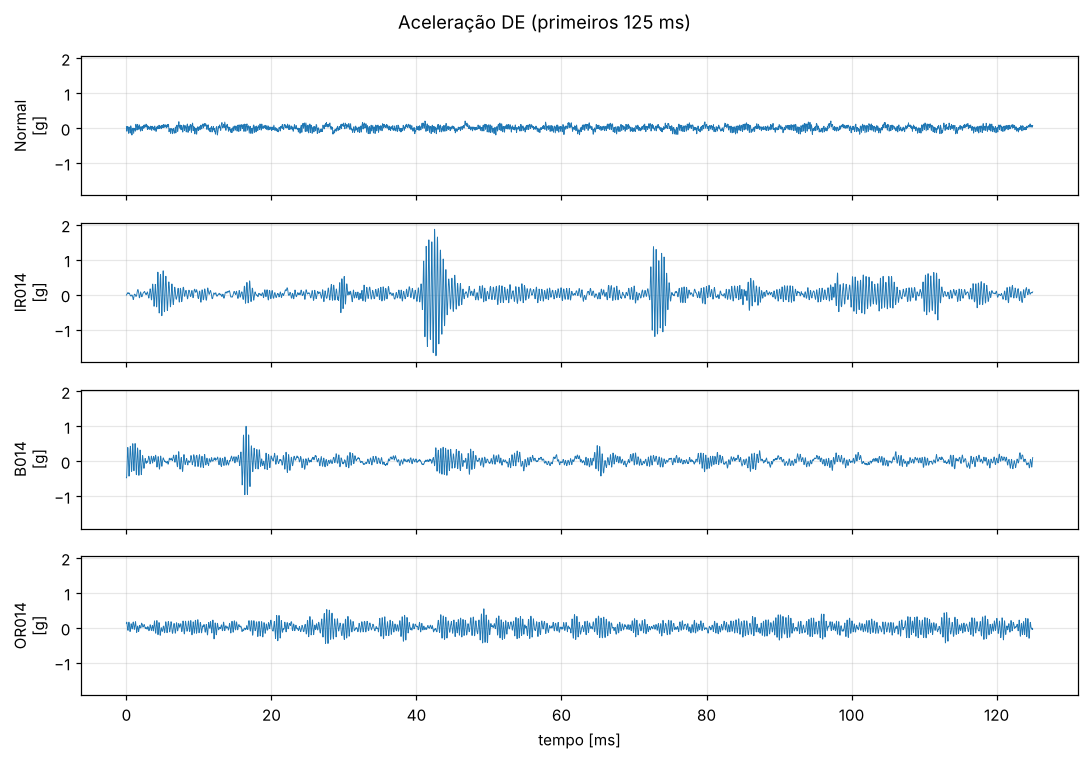

In [3]:
sig={lab:load_signal(fn) for fn,(lab,_) in FILES.items()}
fig,ax=plt.subplots(4,1,figsize=(10,7),sharex=True,sharey=True)
for a,lab in zip(ax,["Normal","IR014","B014","OR014"]):
    x,_=sig[lab] if False else sig[lab]
    a.plot(np.arange(6000)/FS*1000,x[:6000],lw=.6); a.set_ylabel(lab+"\n[g]")
ax[-1].set_xlabel("tempo [ms]"); fig.suptitle("Aceleração DE (primeiros 125 ms)"); plt.tight_layout()

## 3. FFT e espectro de envelope (onde as frequências de falha aparecem)

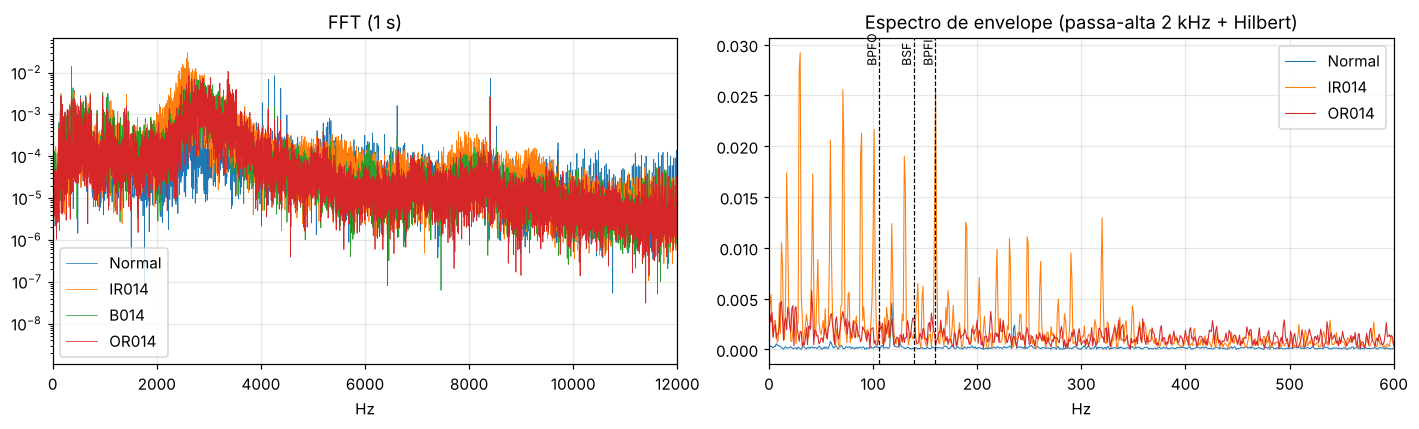

In [4]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
for lab in ["Normal","IR014","B014","OR014"]:
    x,rpm=sig[lab]; w=x[:48000]
    f=np.fft.rfftfreq(len(w),1/FS); P=np.abs(np.fft.rfft(w*np.hanning(len(w))))/len(w)
    ax[0].semilogy(f,P,lw=.5,label=lab)
ax[0].set_xlim(0,12000); ax[0].set_xlabel("Hz"); ax[0].set_title("FFT (1 s)"); ax[0].legend()
for lab,c in zip(["Normal","IR014","OR014"],["C0","C1","C3"]):
    x,rpm=sig[lab]; f,E=envelope_spectrum(x[:48000]); ax[1].plot(f,E,lw=.7,label=lab,color=c)
rpm=1772; fr=rpm/60
for k,v in ORDERS.items(): ax[1].axvline(v*fr,ls="--",c="k",lw=.8); ax[1].text(v*fr,ax[1].get_ylim()[1]*.92,k,rotation=90,ha="right",fontsize=8)
ax[1].set_xlim(0,600); ax[1].set_xlabel("Hz"); ax[1].set_title("Espectro de envelope (passa-alta 2 kHz + Hilbert)"); ax[1].legend()
plt.tight_layout()

**Leitura:** no IR014 o espectro de envelope mostra um pente de linhas espaçadas ≈ 29,5 Hz (rotação do eixo) com picos fortes na região da BPFI (~160 Hz) e harmônicos. O Normal tem envelope plano e muito baixo. Já OR014 e B014 **não** mostram picos claros em BPFO/BSF nesta janela com filtro fixo passa-alta de 2 kHz — a escolha da banda de ressonância (~2,5–3,5 kHz na FFT) influencia muito. Obs.: as features `env_*` são razões em relação ao nível do envelope; no Normal esse nível é minúsculo, então as razões saem altas por ruído e **não** indicam falha.

## 4. Extração de features por janela e divisão sem vazamento

In [5]:
rows=[]
for fn,(lab,_) in FILES.items():
    x,rpm=sig[lab]; W=windows(x); tr,te=block_split(len(W)); trs=set(tr); tes=set(te)
    for i,w in enumerate(W):
        d=extract(w,rpm); d.update(classe=lab,janela=i,rpm=rpm,split="treino" if i in trs else ("teste" if i in tes else "folga")); rows.append(d)
df=pd.DataFrame(rows)
meta=["classe","janela","split","rpm"]; feats=[c for c in df.columns if c not in meta]
G={"tempo":[c for c in feats if not c.startswith(("banda","centroide","env_"))],
   "espectro":[c for c in feats if c.startswith(("banda","centroide"))],
   "envelope":[c for c in feats if c.startswith("env_")]}
print(df.shape, df.split.value_counts().to_dict()); print(len(feats),"features:",{k:len(v) for k,v in G.items()})
df.groupby("classe")[["rms","curtose","fator_crista","env_BPFI_1x","env_BPFO_1x"]].mean().round(3)

(2307, 27) {'treino': 1611, 'teste': 676, 'folga': 20}
23 features: {'tempo': 8, 'espectro': 7, 'envelope': 8}


,rms,curtose,fator_crista,env_BPFI_1x,env_BPFO_1x
classe,,,,,
B007,0.141,0.030,3.626,1.718,1.650
B014,0.143,4.484,5.753,2.152,2.334
B021,0.201,0.309,3.636,2.133,2.069
IR007,0.279,4.362,5.322,4.354,1.423
IR014,0.259,13.970,7.335,2.203,2.354
IR021,0.608,0.874,4.269,2.730,2.149
Normal,0.066,-0.080,3.438,1.029,5.063
OR007,1.060,3.856,4.767,0.666,5.176
OR014,0.137,0.180,3.667,1.733,1.606


**Divisão:** cada sinal é cortado no tempo — primeiros 70% das janelas para treino, últimos ~30% para teste (com 2 janelas de folga). Como as janelas têm 50% de sobreposição, a divisão temporal evita que janelas quase idênticas caiam em treino e teste (comparação na seção 7).

## 5. Classificadores e ablação de features

In [6]:
tr=df[df.split=="treino"]; te=df[df.split=="teste"]
sets={"tempo":G["tempo"],"espectro":G["espectro"],"envelope":G["envelope"],"tempo+espectro":G["tempo"]+G["espectro"],"todas":feats}
models={"Random Forest":lambda:RandomForestClassifier(300,random_state=0),
        "SVM (RBF)":lambda:make_pipeline(StandardScaler(),SVC(C=10)),
        "Reg. logística":lambda:make_pipeline(StandardScaler(),LogisticRegression(max_iter=5000,C=10))}
res=[]
for sn,cols in sets.items():
    for mn,mk in models.items():
        p=mk().fit(tr[cols],tr.classe).predict(te[cols])
        res.append((sn,mn,accuracy_score(te.classe,p),f1_score(te.classe,p,average="macro")))
R=pd.DataFrame(res,columns=["features","modelo","acurácia","F1 macro"])
R.pivot(index="features",columns="modelo",values="acurácia").loc[list(sets)].round(3)

modelo,Random Forest,Reg. logística,SVM (RBF)
features,,,
tempo,0.913,0.871,0.876
espectro,0.987,0.991,0.997
envelope,0.802,0.799,0.815
tempo+espectro,0.991,0.997,0.997
todas,0.991,0.991,0.996


## 6. Melhor modelo: matriz de confusão e importância

SVM, todas as features — acurácia no teste: 0.996


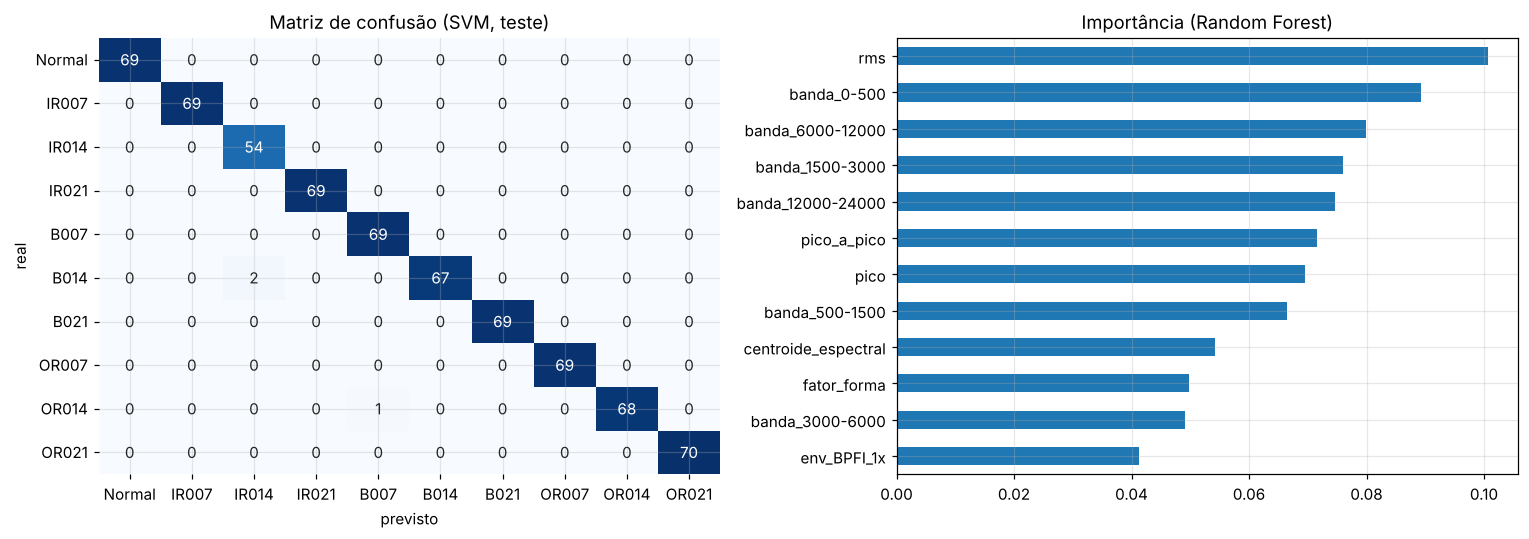

In [7]:
order=["Normal","IR007","IR014","IR021","B007","B014","B021","OR007","OR014","OR021"]
svm=models["SVM (RBF)"]().fit(tr[feats],tr.classe); p=svm.predict(te[feats])
print("SVM, todas as features — acurácia no teste:",round(accuracy_score(te.classe,p),3))
rf=models["Random Forest"]().fit(tr[feats],tr.classe)
fig,ax=plt.subplots(1,2,figsize=(14,5))
sns.heatmap(confusion_matrix(te.classe,p,labels=order),annot=True,fmt="d",cmap="Blues",xticklabels=order,yticklabels=order,ax=ax[0],cbar=False)
ax[0].set_title("Matriz de confusão (SVM, teste)"); ax[0].set_xlabel("previsto"); ax[0].set_ylabel("real")
imp=pd.Series(rf.feature_importances_,feats).sort_values().tail(12); imp.plot.barh(ax=ax[1]); ax[1].set_title("Importância (Random Forest)")
plt.tight_layout()

## 7. Checagem de vazamento: split aleatório vs. split temporal

In [8]:
d2=df[df.split!="folga"]; a,b=train_test_split(d2,test_size=.3,random_state=0,stratify=d2.classe)
m=RandomForestClassifier(300,random_state=0).fit(a[feats],a.classe)
print("RF split ALEATÓRIO :",round(accuracy_score(b.classe,m.predict(b[feats])),3))
print("RF split TEMPORAL  :",round(accuracy_score(te.classe,rf.predict(te[feats])),3))

RF split ALEATÓRIO : 0.993
RF split TEMPORAL  : 0.991


## 8. Conclusões e limites
- Só features no **tempo** (RMS, curtose, fator de crista...) chegam a ~87–91% e confundem severidades/tipos de falha. **Energia por banda espectral** leva a ~99–100% (sozinha já dá 98,7–99,7%).
- As features do **espectro de envelope**, sozinhas, ficam em ~80%: úteis e interpretáveis para pista interna, fracas aqui para pista externa e esfera (filtro fixo de 2 kHz; faltaria otimizar a banda, p.ex. por curtose espectral/kurtogram).
- **Seção 7:** split aleatório (99,3%) e temporal (99,1%) deram praticamente o mesmo, então a sobreposição de janelas não é o problema principal aqui.
- **Limite principal:** há *um único arquivo por classe* (uma carga, um sensor, uma gravação). O teste separa trechos do mesmo registro; **não** mede generalização para outra carga, outra severidade ou outra máquina. Parte dos ~99% pode vir de assinaturas do próprio registro (nível de ruído, banda de ressonância), não só da falha. Esse número é típico do CWRU e **não deve ser extrapolado** para campo.
- Próximos passos mais realistas: treinar em cargas 0/1/2 hp e testar em 3 hp; treinar em um diâmetro e testar em outro; adicionar ruído; usar o canal FE; otimizar a banda do envelope.